# Cell types, growth and UMAP flow

Train a short **multimodal, unbalanced** COATI model on real mouse gastrulation snapshots, then display **E8.5** cell types, instantaneous growth and projected flow on the existing RNA UMAP.

COATI recommends Scanpy-compatible names; Scanpy itself permits other column names.

| Field | Meaning |
| --- | --- |
| `obs["celltype"]` | Supplied categorical cell annotations |
| `obs["time"]` | Numeric times in model-training units |
| `obs["barcode"]` and `obs_names` | Matching, globally unique cell identities |
| `obsm["X_umap"]` | Existing display coordinates in the same row order |

Install with `python -m pip install -e '.[notebooks,visualization]'`. This notebook uses the prepared `gastrulation/rna.h5ad` and `atac.h5ad` from [TraInfBench](https://github.com/shankswang953/TraInfBench/tree/main/data/processed/gastrulation). Source data: Argelaguet and colleagues, [GSE205117](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE205117). Change `DATA_DIR` to your local folder; cell matrices and model checkpoints are not bundled in COATI.

In [1]:
from pathlib import Path
import os
import uuid
import hashlib
import json
import torch
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import coati as ct

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = Path(os.environ.get("COATI_GASTRULATION_DATA", project_dir.parent / "TraInfBench/data/processed/gastrulation"))


## Load paired biological inputs

The prepared inputs contain **35,503 paired cells**, RNA PCA50 and ATAC LSI14. `X_latent` is already scaled: reuse it without applying normalization again. The four model times are 0, 1, 2 and 2.5 for E7.5, E8.0, E8.5 and E8.75.

Verify barcodes and times before attaching ATAC. Missing source annotations are explicitly marked `unknown`; labels are not inferred. Preparation copies the input, preserves source columns and reuses the existing UMAP.

In [2]:
rna = ad.read_h5ad(DATA_DIR / "rna.h5ad")
atac = ad.read_h5ad(DATA_DIR / "atac.h5ad")
assert rna.obs_names.is_unique and rna.obs_names.equals(atac.obs_names)
np.testing.assert_array_equal(rna.obs["time_point_processed"], atac.obs["time_point_processed"])
missing_labels = int(rna.obs["celltype"].isna().sum())
cell_types = rna.obs["celltype"].astype(object).fillna("unknown")
cells = ct.prepare_anndata(
    rna, use_rep="X_latent", time_key="time_point_processed", celltype=cell_types,
    secondary=atac.obsm["X_latent"], secondary_key="X_atac", warn=False,
)
assert cells.obs_names.equals(rna.obs_names)
np.testing.assert_array_equal(cells.obsm["X_latent"], rna.obsm["X_latent"])
np.testing.assert_array_equal(cells.obsm["X_umap"], rna.obsm["X_umap"])
print(f"Paired cells: {cells.n_obs:,}; missing annotations marked unknown: {missing_labels:,}")
cells.obs.groupby(["stage", "time"], observed=True).size().rename("Cells").to_frame()


Paired cells: 35,503; missing annotations marked unknown: 3,015


,,Cells
stage,time,
E7.5,0.0,9018
E8.0,1.0,7796
E8.5,2.0,11470
E8.75,2.5,7219


## Train for 1,000 iterations

`multimodal=True` fits a time-conditioned FiLM map on paired RNA/ATAC before vector-field training. `balanced=False` enables growth and population-mass change. All four stages are used; this is a dynamics example, not a held-out reconstruction experiment.

The explicit settings below are a short CPU demonstration. The secondary weight is 0.35; population counts are observed sampling counts, not absolute biological population sizes. Changing `balanced` to `True` produces a motion-only model.

In [3]:
config = ct.Config(
    multimodal=True, balanced=False, iterations=1000,
    batch_size=128, hidden_dim=128, learning_rate=1e-3,
    secondary_weight=.35, matching_weight=50., energy_weight=1.,
    manifold_weight=.1, sync_density_loss=True, seed=0,
)
output_dir = Path("outputs") / ("gastrulation-dynamics-" + uuid.uuid4().hex[:8])
result = ct.train_vector_field(cells, config, output_dir=output_dir)
print("Training times:", result.data.times)
print("Output:", result.output_dir)


Training times: [0.  1.  2.  2.5]
Output: /Users/jingfeng/local/project/COATI/outputs/gastrulation-dynamics-40c4dae2


## View one stage on UMAP

Show all **11,470 E8.5 cells at t = 2**. Both panels share coordinates and the same projected COATI velocity field. Cell-type names appear in a common legend to keep the biological plot readable. No toy labels or new UMAP are generated.

The right panel colors **instantaneous $d\log w/dt$**, including the saved ODE's growth multiplier. It is not cumulative weight, cell count or measured proliferation. Streams use a local projection of RNA50 velocities into the existing UMAP; their display resembles RNA velocity, but does not use scVelo's splicing or transition model.

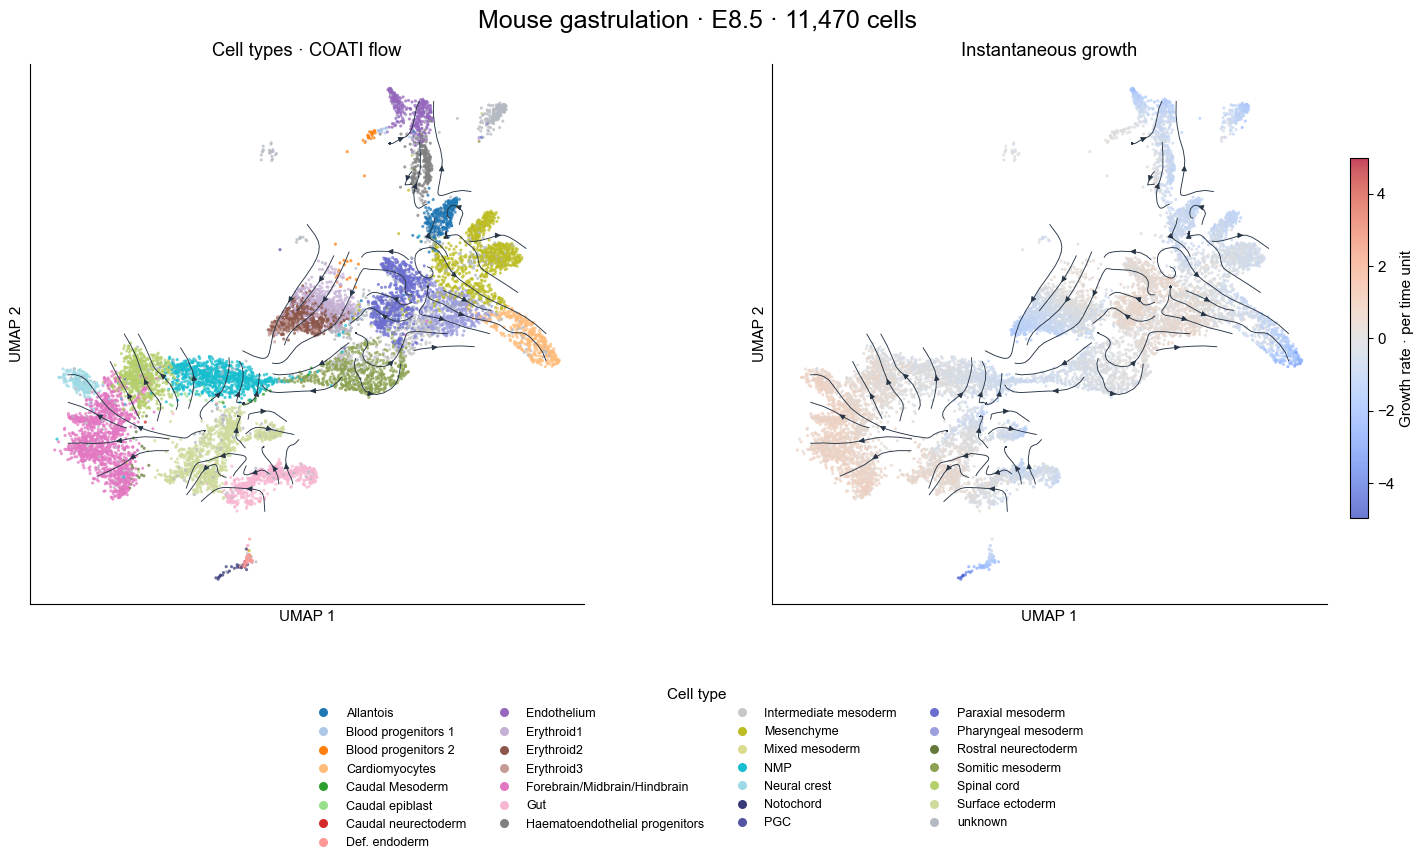

In [4]:
stage_cells = cells[cells.obs["stage"] == "E8.5"].copy()
names = stage_cells.obs["celltype"].cat.categories
colors = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
palette = dict(zip(names, colors))
palette["unknown"] = "#b5bac2"
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
result.plot_dynamics(
    stage_cells, axes=axes, labels=False, palette=palette,
    point_size=5, alpha=.75, density=1.3, linewidth=.65, arrow_size=.8, grid_size=60,
)
legend = axes[0].get_legend()
fig.legend(legend.legend_handles, [text.get_text() for text in legend.get_texts()],
           loc="lower center", bbox_to_anchor=(.5, .015), ncol=4,
           frameon=False, fontsize=9, title="Cell type", markerscale=1.3)
legend.remove()
fig.suptitle(f"Mouse gastrulation · E8.5 · {stage_cells.n_obs:,} cells", fontsize=18, y=.96)
axes[0].set_position([.04, .30, .40, .60])
axes[1].set_position([.52, .30, .40, .60])
fig.axes[2].set_position([.935, .36, .012, .47])
fig.savefig(result.output_dir / "dynamics_umap.png", dpi=180, bbox_inches="tight")
fig.savefig(result.output_dir / "dynamics_umap.pdf", bbox_inches="tight")
plt.show()


## Inspect growth and store aligned results

Evaluate growth on the original training features. `write_dynamics(copy=True)` adds primary velocity, projected UMAP velocity and instantaneous growth to a new AnnData, retaining barcodes, supplied labels and row order. The numerical values remain available without display autoscaling.

In [5]:
growth = result.compute_growth(stage_cells.obsm["X_latent"], time=stage_cells.obs["time"].to_numpy())
stored = result.write_dynamics(stage_cells, copy=True)
assert "coati_growth" not in cells.obs and "coati_velocity" not in cells.obsm
assert stored.obs_names.equals(stage_cells.obs_names)
np.testing.assert_array_equal(stored.obs["coati_growth"], growth)
assert np.isfinite(stored.obsm["coati_velocity_umap"]).all()
stored.write_h5ad(result.output_dir / "dynamics.h5ad")
stored.obs.groupby("celltype", observed=True)["coati_growth"].agg(["count", "median"])


,count,median
celltype,,
Allantois,347,-0.741384
Blood progenitors 1,22,-0.036509
Blood progenitors 2,49,0.165059
Cardiomyocytes,372,-0.858906
Caudal Mesoderm,12,-0.804097
Caudal epiblast,15,-0.202079
Caudal neurectoderm,1,0.299355
Def. endoderm,49,-1.349994
Endothelium,337,-0.894114


## Verify the saved model

Reload the checkpoint and verify exactly identical velocities and growth on the displayed cells. Read back the stored AnnData and check its values and row identities. The standalone script independently reproduces this workflow with `--iterations 1000`, or checks an existing run with `--reuse`.

In [6]:
restored = ct.load_result(result.output_dir)
points, times = stage_cells.obsm["X_latent"], stage_cells.obs["time"].to_numpy()
np.testing.assert_array_equal(result.compute_velocity(points, time=times), restored.compute_velocity(points, time=times))
np.testing.assert_array_equal(growth, restored.compute_growth(points, time=times))
reread = ad.read_h5ad(result.output_dir / "dynamics.h5ad")
assert reread.obs_names.equals(stage_cells.obs_names)
np.testing.assert_array_equal(reread.obsm["X_umap"], stage_cells.obsm["X_umap"])
np.testing.assert_array_equal(reread.obs["coati_growth"], growth)
np.testing.assert_array_equal(reread.obsm["coati_velocity"], stored.obsm["coati_velocity"])
np.testing.assert_array_equal(reread.obsm["coati_velocity_umap"], stored.obsm["coati_velocity_umap"])
checkpoint = torch.load(result.output_dir / "checkpoints/path_param.pth", map_location="cpu", weights_only=False)
map_report = json.loads((result.output_dir / "map/report.json").read_text())
validation = {
    "dataset": "gastrulation", "accession": "GSE205117", "training_cells": cells.n_obs,
    "times": result.data.times.tolist(), "checkpoint_iterations": checkpoint["iteration"],
    "plot_stage": "E8.5", "plot_cells": stage_cells.n_obs, "config": result.metadata["config"],
    "source_sha256": {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
                      for name in ("rna.h5ad", "atac.h5ad")},
    "map_report": map_report, "growth_definition": "d log(weight) / dt",
    "growth_range": [float(growth.min()), float(growth.max())],
    "exact_checkpoint_reload": True, "anndata_roundtrip": True,
}
(result.output_dir / "notebook_validation.json").write_text(json.dumps(validation, indent=2) + "\n")
print("Checkpoint iterations:", checkpoint["iteration"])
print("Map validation:", map_report["status"])
print("Exact checkpoint reload and AnnData roundtrip: passed")


Checkpoint iterations: 1000
Map validation: passed
Exact checkpoint reload and AnnData roundtrip: passed


## Reuse the workflow

```bash
python examples/run_gastrulation_dynamics.py \
    --data-dir /path/to/gastrulation \
    --output outputs/gastrulation-dynamics --iterations 1000
```

For your own AnnData, select the same prepared representation used for training, map your time/celltype columns with `ct.prepare_anndata`, and provide row-paired secondary features only for multimodal fitting. `result.plot_growth(stage_cells, show_velocity=True)` gives the growth panel alone. Arrays can also be assembled with `ct.prepare_anndata(features, time=times, celltype=labels, barcode=ids, umap=coordinates)`.

This one-seed short run demonstrates the biological-data workflow. It does not establish convergence, lineage accuracy or experimental growth rates. Use the saved map diagnostics before interpreting secondary-modality consistency.